# Fiche 4 — Lire `describe()`, interpréter une distribution, automatiser avec une fonction

| | |
|---|---|
| 🎯 **Objectif** | Savoir expliquer chaque ligne de `describe()` et décrire une distribution en une phrase |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiche 2 |
| 🔗 **Dans le projet** | Exercice partie 3, étape 2 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.io import load_tables

viz.apply_style()
pd.set_option("display.max_colwidth", 70)

pays_indicateurs = pd.read_csv("../data/processed/pays_indicateurs.csv", index_col=0)

## 1. `describe()` ligne par ligne

In [2]:
internet = pays_indicateurs["Utilisateurs d'internet (% population)"]
internet.describe().round(1)

count    203.0
mean      39.9
std       28.5
min        0.0
25%       12.5
50%       37.5
75%       62.1
max       96.2
Name: Utilisateurs d'internet (% population), dtype: float64

| Ligne | Signification | Ici (internet, % de la population) |
|---|---|---|
| `count` | nombre de valeurs **non manquantes** | pays renseignés (et non le nombre total de pays !) |
| `mean` | moyenne : somme ÷ nombre | sensible aux valeurs extrêmes |
| `std` | écart-type : dispersion moyenne autour de la moyenne | grand ⇒ pays très différents |
| `min` / `max` | extrêmes | à vérifier : sont-ils plausibles ? |
| `25%` (Q1) | 25 % des pays sont **en dessous** | |
| `50%` (médiane) | la moitié des pays est en dessous, la moitié au-dessus | le « pays du milieu » |
| `75%` (Q3) | 75 % des pays sont en dessous | |

**Q3 − Q1** est l'**écart interquartile** : la largeur de la « moitié centrale » des pays.

## 2. Moyenne vs médiane : le détecteur d'asymétrie

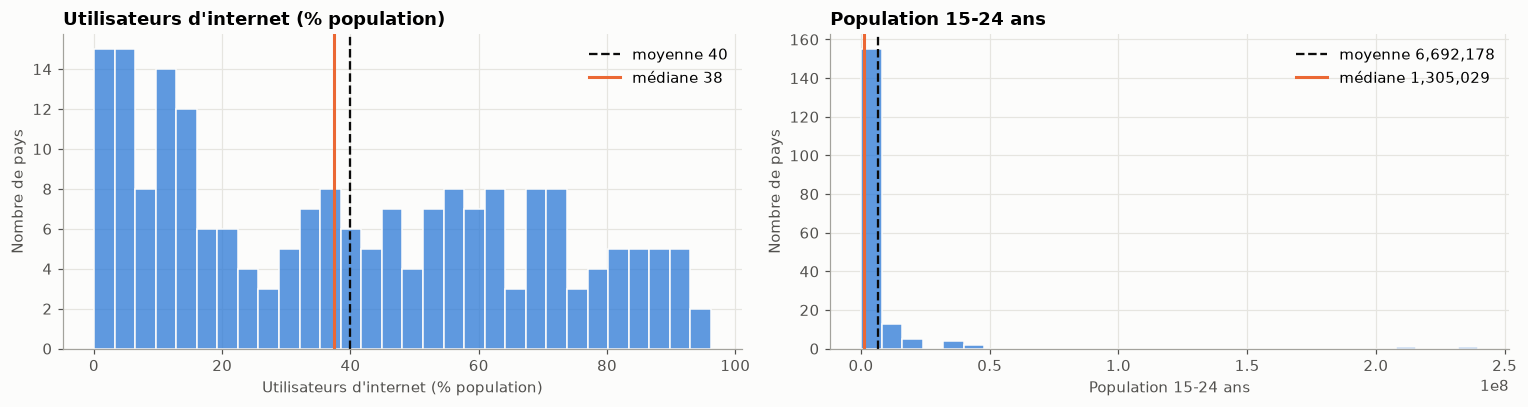

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col in zip(axes, ["Utilisateurs d'internet (% population)", "Population 15-24 ans"]):
    v = pays_indicateurs[col].dropna()
    sns.histplot(v, bins=30, ax=ax, color=viz.BLUE, edgecolor=viz.SURFACE)
    ax.axvline(v.mean(), color=viz.TEXT, linestyle="--", label=f"moyenne {v.mean():,.0f}")
    ax.axvline(v.median(), color=viz.ORANGE, linewidth=2, label=f"médiane {v.median():,.0f}")
    ax.set(title=col, ylabel="Nombre de pays")
    ax.legend()
fig.tight_layout()
plt.show()

- **Internet** : moyenne ≈ médiane ⇒ distribution plutôt **symétrique**. La moyenne représente bien un pays typique.
- **Population 15-24 ans** : moyenne ≫ médiane ⇒ **asymétrie à droite**. Quelques géants (Inde, Chine) tirent la
  moyenne vers le haut, et la moyenne ne décrit **aucun** pays réel.

> Règle pratique : si la moyenne est très éloignée de la médiane, on décrit la distribution par la **médiane** et
> les quartiles, et on la trace en **échelle logarithmique**.

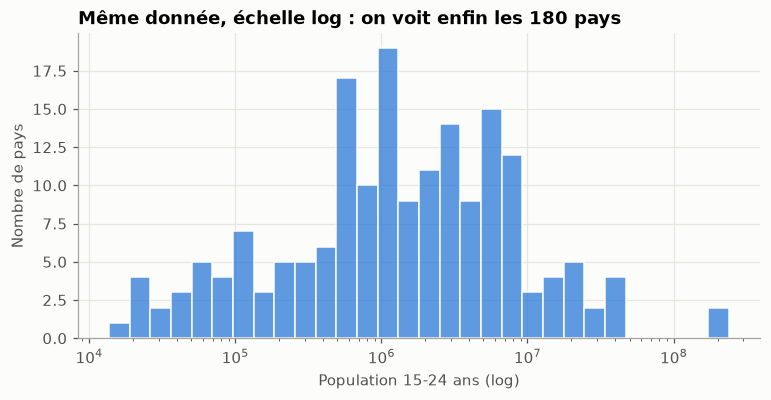

In [4]:
v = pays_indicateurs["Population 15-24 ans"].dropna()
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(v, bins=30, log_scale=True, ax=ax, color=viz.BLUE, edgecolor=viz.SURFACE)
ax.set(title="Même donnée, échelle log : on voit enfin les 180 pays", xlabel="Population 15-24 ans (log)",
       ylabel="Nombre de pays")
plt.show()

## 3. Les valeurs extrêmes : le boxplot et la règle de 1,5 × IQR

Un **boxplot** résume `describe()` en une image : la boîte va de Q1 à Q3, le trait central est la médiane, et les
points isolés sont au-delà de **Q3 + 1,5 × (Q3 − Q1)** (ou en dessous de Q1 − 1,5 × IQR).

Q1 = 4.5  Q3 = 12.1  borne haute = 23.6


,Short Name,Chômage (% population active)
Country Code,,
BIH,Bosnia and Herzegovina,27.500000
ESP,Spain,24.400000
GMB,The Gambia,29.700001
GRC,Greece,24.400000
LSO,Lesotho,25.299999
MKD,Macedonia,31.000000
SLB,Solomon Islands,31.000000
SWZ,Swaziland,27.200001
ZAF,South Africa,24.700001


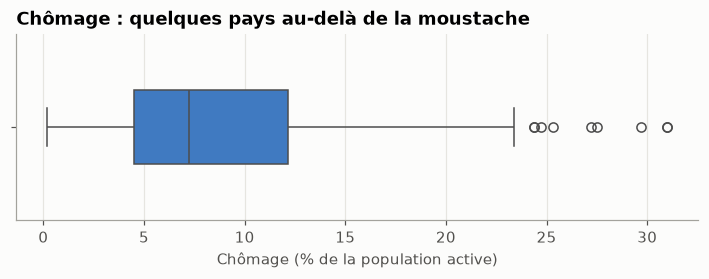

In [5]:
chomage = pays_indicateurs["Chômage (% population active)"]
q1, q3 = chomage.quantile([0.25, 0.75])
borne_haute = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:.1f}  Q3 = {q3:.1f}  borne haute = {borne_haute:.1f}")
display(pays_indicateurs.loc[chomage > borne_haute, ["Short Name", "Chômage (% population active)"]])

fig, ax = plt.subplots(figsize=(8, 2.2))
sns.boxplot(x=chomage, ax=ax, color=viz.BLUE, width=0.4)
ax.set(title="Chômage : quelques pays au-delà de la moustache", xlabel="Chômage (% de la population active)")
plt.show()

⚠️ **Valeur extrême ≠ erreur.** 27 % de chômage en Bosnie-Herzégovine ou 24 % en Grèce et en Espagne après la
crise de 2008, c'est une réalité économique, pas une faute
de frappe. On ne supprime une valeur que si elle est **impossible** (un taux de 420 %), jamais parce qu'elle
« dépasse ».

## 4. Automatiser : une fonction + une boucle `for`

On a écrit le même code trois fois ci-dessus : c'est le signal pour en faire une **fonction**.

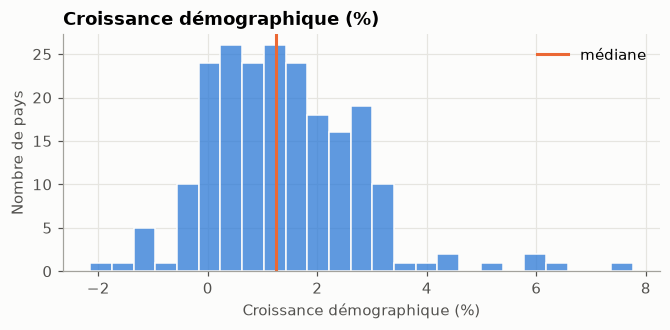

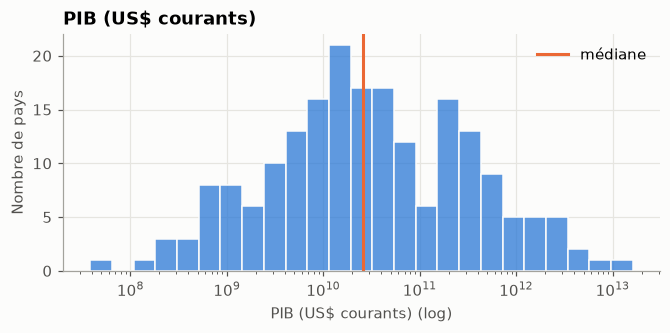

,Croissance démographique (%),PIB (US$ courants)
count,214.00,1.990000e+02
mean,1.38,3.715327e+11
std,1.40,1.428972e+12
min,-2.15,3.832236e+07
25%,0.45,6.244054e+09
50%,1.24,2.569416e+10
75%,2.22,2.002337e+11
max,7.76,1.615526e+13


In [6]:
def decrire(valeurs: pd.Series, log: bool = False) -> pd.Series:
    stats = valeurs.describe()
    fig, ax = plt.subplots(figsize=(7, 2.8))
    sns.histplot(valeurs.dropna(), bins=25, log_scale=log, ax=ax, color=viz.BLUE, edgecolor=viz.SURFACE)
    ax.axvline(stats["50%"], color=viz.ORANGE, linewidth=2, label="médiane")
    ax.set(title=valeurs.name, xlabel=valeurs.name + (" (log)" if log else ""), ylabel="Nombre de pays")
    ax.legend()
    plt.show()
    return stats


resultats = {}
for colonne in ["Croissance démographique (%)", "PIB (US$ courants)"]:
    resultats[colonne] = decrire(pays_indicateurs[colonne], log=colonne.startswith("PIB"))
pd.DataFrame(resultats).round(2)

Avantages de la fonction : un seul endroit à corriger, un traitement **identique** pour tous les indicateurs, et
un code plus court donc plus lisible. Dans le projet, la version complète est `edstats.analysis.describe_and_plot`.

### ✍️ À toi de jouer

Applique `decrire` au **taux brut de scolarisation supérieure**. Décris la distribution en **une phrase** destinée à Mark (non technique).

In [7]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
decrire(pays_indicateurs["Taux brut de scolarisation supérieure (%)"])
```

Exemple de phrase : « Dans la moitié des pays, moins d'un jeune sur trois en âge d'étudier est inscrit dans le supérieur, mais un quart des pays dépasse 60 % : le marché universitaire est très inégal selon les pays. » Vérifie les chiffres dans ta sortie : ceux de la phrase sont des ordres de grandeur.
</details>

## ✅ À retenir

1. `count` = valeurs renseignées ; Q1 / médiane / Q3 = 25 % / 50 % / 75 % des pays en dessous.
2. Moyenne ≫ médiane ⇒ asymétrie à droite ⇒ on raisonne en médiane et en échelle log.
3. Boxplot et 1,5 × IQR pour **repérer** les valeurs extrêmes ; on ne les supprime que si elles sont impossibles.
4. Code répété ⇒ une fonction ; plusieurs indicateurs ⇒ une boucle `for`.